# **Mini projet UE A**

**The contributors :**
- Badssi Chaimae
- Ezzahraoui Hajar
- Samrani Mohamed Yazid
- Sefyani Diae

In [40]:
#imports :
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import seaborn as sns
from sklearn.decomposition import PCA
import general as gn

## 1. Loading Data and Data preparation

Let's have a look into the spam data

In [41]:
columns = [
    "word_freq_make",
    "word_freq_address",
    "word_freq_all",
    "word_freq_3d",
    "word_freq_our",
    "word_freq_over",
    "word_freq_remove",
    "word_freq_internet",
    "word_freq_order",
    "word_freq_mail",
    "word_freq_receive",
    "word_freq_will",
    "word_freq_people",
    "word_freq_report",
    "word_freq_addresses",
    "word_freq_free",
    "word_freq_business",
    "word_freq_email",
    "word_freq_you",
    "word_freq_credit",
    "word_freq_your",
    "word_freq_font",
    "word_freq_000",
    "word_freq_money",
    "word_freq_hp",
    "word_freq_hpl",
    "word_freq_george",
    "word_freq_650",
    "word_freq_lab",
    "word_freq_labs",
    "word_freq_telnet",
    "word_freq_857",
    "word_freq_data",
    "word_freq_415",
    "word_freq_85",
    "word_freq_technology",
    "word_freq_1999",
    "word_freq_parts",
    "word_freq_pm",
    "word_freq_direct",
    "word_freq_cs",
    "word_freq_meeting",
    "word_freq_original",
    "word_freq_project",
    "word_freq_re",
    "word_freq_edu",
    "word_freq_table",
    "word_freq_conference",
    "char_freq_;",
    "char_freq_(",
    "char_freq_[",
    "char_freq_!",
    "char_freq_$",
    "char_freq_#",
    "capital_run_length_average",
    "capital_run_length_longest",
    "capital_run_length_total",
    "spam"
]


In [42]:
df = pd.read_csv("spambase.data", header=None, names=columns)
df

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,spam
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.000,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.000,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.010,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.000,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.000,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4596,0.31,0.00,0.62,0.0,0.00,0.31,0.00,0.00,0.00,0.00,...,0.000,0.232,0.0,0.000,0.000,0.000,1.142,3,88,0
4597,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.00,...,0.000,0.000,0.0,0.353,0.000,0.000,1.555,4,14,0
4598,0.30,0.00,0.30,0.0,0.00,0.00,0.00,0.00,0.00,0.00,...,0.102,0.718,0.0,0.000,0.000,0.000,1.404,6,118,0
4599,0.96,0.00,0.00,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.000,0.057,0.0,0.000,0.000,0.000,1.147,5,78,0


In [43]:
df.info()
print("Duplicated rows :", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4601 entries, 0 to 4600
Data columns (total 58 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   word_freq_make              4601 non-null   float64
 1   word_freq_address           4601 non-null   float64
 2   word_freq_all               4601 non-null   float64
 3   word_freq_3d                4601 non-null   float64
 4   word_freq_our               4601 non-null   float64
 5   word_freq_over              4601 non-null   float64
 6   word_freq_remove            4601 non-null   float64
 7   word_freq_internet          4601 non-null   float64
 8   word_freq_order             4601 non-null   float64
 9   word_freq_mail              4601 non-null   float64
 10  word_freq_receive           4601 non-null   float64
 11  word_freq_will              4601 non-null   float64
 12  word_freq_people            4601 non-null   float64
 13  word_freq_report            4601 

In [44]:
df = df.drop_duplicates()

We can see that in the spam data we have 4601 samples, and 58 numerical features.

We verify (as mentioned in spambase.DOCUMENTATION) that the values of the attributes are heterogen (capital_run_length_total and capital_run_length_longest are in the ordre of 10 and 100 respectively unlike the other attributes who are in the ordre of 1/10).

We also check that all the attributes are full (no missing values).

Since we found that we have duplicates and they are not useful for our study we delete them and keep just one ligne

In [45]:
#To load the spam data already split and in numpy (so it's ready for ML)
X = df.drop(columns="spam").to_numpy()
y = df["spam"].to_numpy()

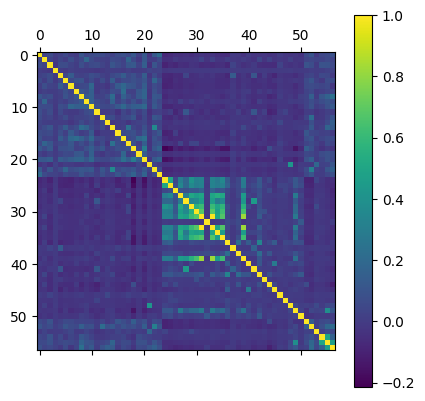

In [46]:
correlations = np.corrcoef(X.T)
plt.matshow(correlations)
plt.colorbar()
plt.show()

In [47]:
# We can use the NumPy correlation matrix we already calculated
# Get the feature names (excluding the label 'spam' which is the last column)
feature_names = df.columns[:-1]
a=0.8
# Find the pairs with correlation coefficient > 0.8
high_corr_pairs = []
for i in range(len(feature_names)):
    for j in range(i + 1, len(feature_names)):
        coeff = correlations[i, j]
        if coeff > a or coeff <-a:
            high_corr_pairs.append({
                'Feature 1': feature_names[i],
                'Feature 2': feature_names[j],
                'Correlation': coeff
            })

# Display the results using a DataFrame for clean formatting
display(pd.DataFrame(high_corr_pairs))

,Feature 1,Feature 2,Correlation
0,word_freq_857,word_freq_415,0.994875
1,word_freq_857,word_freq_direct,0.824206
2,word_freq_415,word_freq_direct,0.820837


We also see here that the majority of attributes are far from being correlated between each other , but there are 3 pairs of attributes that have a correlation coefficient higher 0.8 as showed in the table above.

Since we have 57 features in the database and beacause there are some correlation between the features , we will use PCA method to reduce the dimension of X to the most useful and meaningfull features for learning.

**Outliers visualization**

We realized that in our dataset we have some outliers in some features (for example in word_freq_free as you can see below)

This motivates us to use the log1 transformation $log1(x)=log(1+x)$

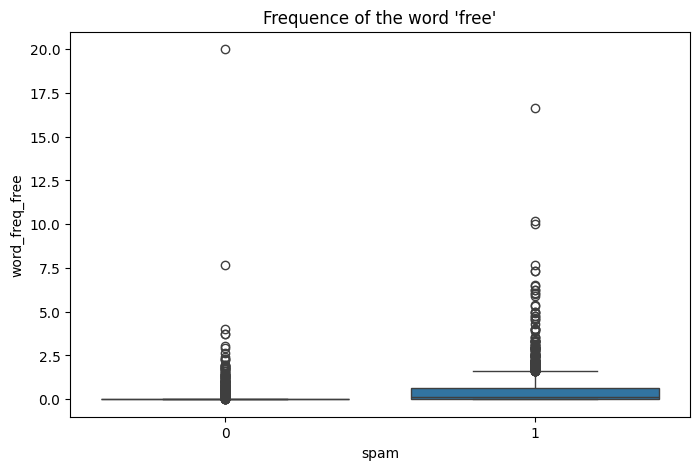

In [48]:
 #spam vs non-spam for a feature
plt.figure(figsize=(8,5))

sns.boxplot(
   data=df,
    x='spam',
    y='word_freq_free'
)

plt.title("Frequence of the word 'free'")
plt.show()

# **Data Split**

Let's divide the dataset into a training, test and validation set (70%, 15%, 15%). All models will be trained on the training set and to determine best hyperparameters we'll use validation set. The test set will be used only for final model evaluation.
As its mentioned in spambase.DOCUMENTATION 60.6% of the mails are non-spam,in order for the train/test split to be representative of this imbalance, we stratified by the spam label.



In [49]:
# Split data
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.3,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    stratify=y_temp,
    random_state=42
)



For the spambase,we decided to try two approaches, the first is just to use the standerscaler and the second one is to use the log1 transformation $log1(x)=log(1+x)$ before using the standerscaler, because the log1 transformation reduces skewness by compressing large values(so extreme values have less influence-they exist in some attributes like capital_run_length_total).

In [50]:
X_train_log1=np.log1p(X_train)
X_val_log1=np.log1p(X_val)
X_test_log1=np.log1p(X_test)
X_temp_log1=np.log1p(X_temp)

scaler = StandardScaler().fit(X_train)
X_train_sc = scaler.transform(X_train)
X_val_sc = scaler.transform(X_val)
X_test_sc = scaler.transform(X_test)
X_temp_sc = scaler.transform(X_temp)

scaler_log1= StandardScaler().fit(X_train_log1)
X_train_log1_sc = scaler_log1.transform(X_train_log1)
X_val_log1_sc = scaler_log1.transform(X_val_log1)
X_test_log1_sc = scaler_log1.transform(X_test_log1)
X_temp_log1_sc=scaler_log1.transform(X_temp_log1)

pca=PCA(n_components=0.95)
X_train_final=pca.fit_transform(X_train_sc)
X_val_final=pca.transform(X_val_sc)
X_test_final=pca.transform(X_test_sc)
X_temp_final=pca.transform(X_temp_sc)

pca_log1=PCA(n_components=0.95)

X_train_log1_final=pca.fit_transform(X_train_log1_sc)
X_val_log1_final=pca.transform(X_val_log1_sc)
X_test_log1_final=pca.transform(X_test_log1_sc)
X_temp_log1_final=pca.transform(X_temp_log1_sc)




## 2. Classification models

###2.1 Logistic Regression

Logistic Regression computes a weighted sum of the attributes and transforms it into a probability of being spam (with the sigmoid function). An email is classified as spam if this probability is above 0.5. There is no hyperparameter to tune in our workflow, so we directly train it.

####2.1.1 Without log1 Transformation

In [52]:
lgs, test_acc = gn.logistic_regression_model(X_train_final, y_train, X_temp_final, y_temp)
print(f"test accuracy = {test_acc:.4f}")

test accuracy = 0.9216


2.1.2 With log1 Transformation

In [53]:
lgs, test_acc = gn.logistic_regression_model(X_train_log1_final, y_train, X_temp_log1_final, y_temp)

print(f"test accuracy = {test_acc:.4f}")

test accuracy = 0.9335


Here we can see the interest of adding the log1 transformation , using it we had about 1.1% of added accuracy. So from now on we will be using the log1 transformation on all the other methods.

### 2.2 K-Nearest Neighbors (KNN)

KNN classifies an email by looking at its k closest emails in the training set and taking the majority class. We will try it with and without log1 transformation.

The only hyper-parameter is **k** :
- k too small (ex: 1) : the model follows the noise of the data (overfitting).
- k too large : the model becomes too smooth and ignores local structure (underfitting).


In [54]:
best_k, best_accuracy = gn.best_k(X_train_log1_final, y_train, X_val_log1_final, y_val, max_k=30)
knn_model, accuracy=gn.knn_model(X_train_log1_final, y_train, X_test_log1_final, y_test, best_k)
print(accuracy)
print(f"Best k: {best_k}, Best Accuracy: {best_accuracy}")


0.9034810126582279
Best k: 10, Best Accuracy: 0.9381933438985737


### 2.3 SVM

The SVM looks for the hyperplane that separates spam from non-spam with the largest margin. We tune the **kernel** (linear, polynomial, RBF, sigmoid) and the regularization parameter **C** (small C : wide margin but more errors allowed, large C : fewer errors allowed but risk of overfitting).

In [57]:
best_kernel,best_c,best_accuracy=gn.best_svm_kernel_C(X_train_log1_final, y_train, X_val_log1_final, y_val, kernels=['linear', 'poly', 'rbf', 'sigmoid'], C_values=[0.1, 1, 10])
print(f"Best kernel: {best_kernel}")
print(f"Best C: {best_c}")
print(f"Best accuracy: {best_accuracy}")
svm_model, accuracy=gn.svm_model(X_train_log1_final, y_train, X_test_log1_final, y_test, best_kernel, best_c)
print(f"SVM accuracy: {accuracy}")

Best kernel: linear
Best C: 0.1
Best accuracy: 0.9461172741679873
SVM accuracy: 0.9224683544303798


### 2.4 Decision tree
A decision tree asks a sequence of questions on the attributes (ex: "is the frequency of "!" higher than some number?"). We tune the maximum depth and the minimum number of samples needed to split a node to control the overfitting.

In [58]:
best_max_depth, best_min_samples_split, best_accuracy=gn.best_decision_tree_hyperparameters(X_train_log1_final, y_train, X_val_log1_final, y_val, max_depth_list=[None, 5, 10], min_samples_split_list=[2, 5, 10])
dt_model, accuracy=gn.decision_tree_model(X_train_log1_final, y_train, X_test_log1_final, y_test, best_max_depth, best_min_samples_split)
print(f"Best max_depth: {best_max_depth}, Best min_samples_split: {best_min_samples_split}, Best Accuracy: {best_accuracy}")
print(f"Decision Tree accuracy: {accuracy}")

Best max_depth: 5, Best min_samples_split: 10, Best Accuracy: 0.93026941362916
Decision Tree accuracy: 0.9066455696202531


### 2.5 Random forest

A Random Forest averages many decision trees trained on random parts of the data, which reduces the overfitting of a single tree. We tune the number of trees and their maximum depth.


In [63]:
best_n_estimators, best_max_depth, best_accuracy = gn.best_random_forest_hyperparameters(X_train_log1_final, y_train, X_val_log1_final, y_val, n_estimators_list=range(10, 21), max_depth_list=range(3, 11))
rf_model, accuracy = gn.random_forest_model(X_train_log1_final, y_train, X_test_log1_final, y_test, best_n_estimators, best_max_depth)
print(f"Best n_estimators: {best_n_estimators}, Best max_depth: {best_max_depth}, Best Accuracy: {best_accuracy}")
print(f"Random Forest accuracy: {accuracy}")

Best n_estimators: 20, Best max_depth: 9, Best Accuracy: 0.9508716323296355
Random Forest accuracy: 0.9161392405063291


###2.6 Gradient boosting

Gradient Boosting builds small trees one after the other, each one correcting the mistakes of the previous ones. We tune the number of trees, the learning rate and the depth of the trees.

In [66]:
best_n_estimators,best_learning_rate,best_max_depth,best_accuracy=gn.best_gradient_boosting_hyperparameters(
    X_train_log1_final,y_train,
    X_val_log1_final,y_val,
    n_estimators_list=[50, 100, 200],
    learning_rate_list=[0.01, 0.1, 0.2],
    max_depth_list=[1, 3, 5]
)
gb_model, accuracy= gn.gradient_boosting_model(
    X_train_log1_final,
    y_train,
    X_test_log1_final,
    y_test,
    best_n_estimators,
    best_learning_rate,
    best_max_depth
)
print(f"Best n_estimators: {best_n_estimators}, best_learning_rate: {best_learning_rate},best_max_depth: {best_max_depth}, Best Accuracy: {best_accuracy}")
print(f"gradient boosting accuracy: {accuracy}")

Best n_estimators: 200, best_learning_rate: 0.1,best_max_depth: 5, Best Accuracy: 0.9572107765451664
gradient boosting accuracy: 0.9193037974683544


###2.7 MLP Neural Network

In [67]:
best_hidden_layer_sizes,best_alpha,best_accuracy=gn.best_mlp_hyperparameters(
    X_train_log1_final,
    y_train,
    X_val_log1_final,
    y_val,
    hidden_layer_sizes_list=[(50,), (100,), (100,50)],
    alpha_list=[0.0001, 0.001, 0.01]
)
mlp_model,accuracy=gn.mlp_model(
    X_train_log1_final,
    y_train,
    X_test_log1_final,
    y_test,
    best_hidden_layer_sizes,
    best_alpha
)
print(f"best_hidden_layer_sizes:{best_hidden_layer_sizes},best_alpha:{best_alpha},best_accuracy:{best_accuracy}")
print(f"MLP accuracy:{accuracy}")

best_hidden_layer_sizes:(50,),best_alpha:0.001,best_accuracy:0.9603803486529319
MLP accuracy:0.9145569620253164


## 3. Comparison of the models

**3.1 Confusion matrix and the different types of errors**


                 Model  Accuracy  Precision    Recall  F1-score  \
1  Logistic Regression  0.922468   0.917695  0.884921  0.901010   
6                  SVM  0.922468   0.921162  0.880952  0.900609   
4    Gradient Boosting  0.919304   0.903614  0.892857  0.898204   
5                  MLP  0.914557   0.886719  0.900794  0.893701   
3        Random Forest  0.916139   0.912863  0.873016  0.892495   
2        Decision Tree  0.906646   0.903766  0.857143  0.879837   
0                  KNN  0.903481   0.924444  0.825397  0.872117   

   False Positives  False Negatives  
1               20               29  
6               19               30  
4               24               27  
5               29               25  
3               21               32  
2               23               36  
0               17               44  


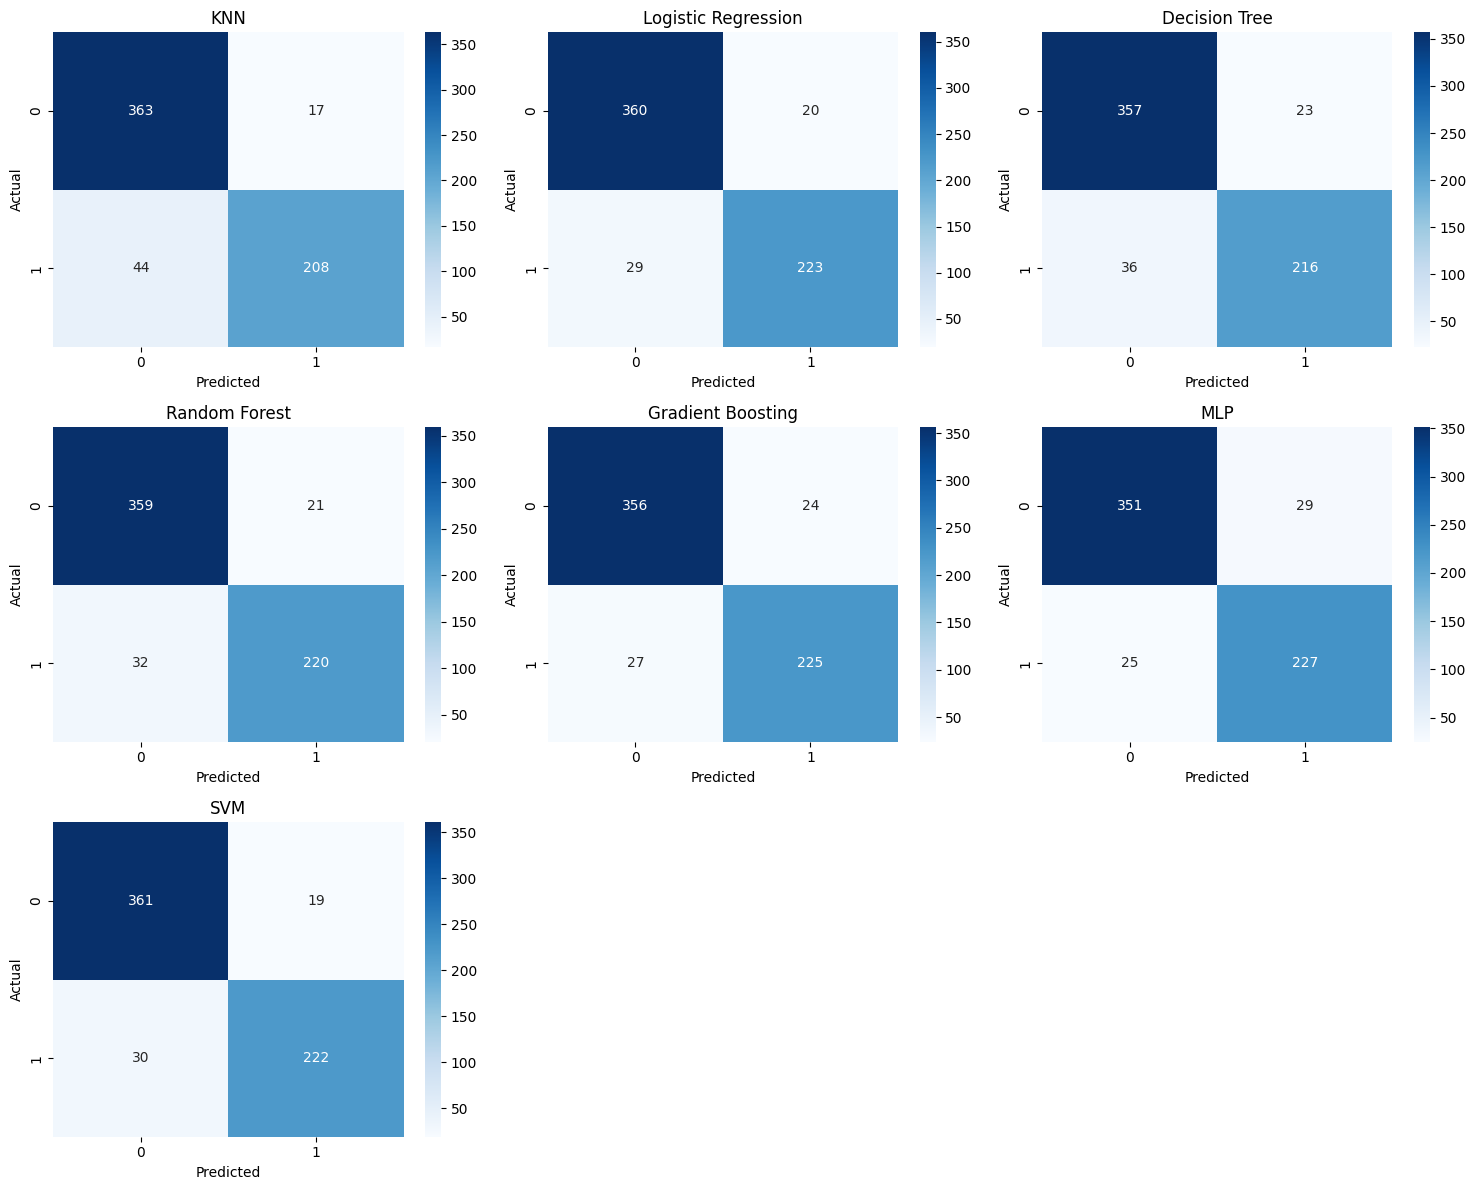

In [68]:
models = {
    "KNN": knn_model,
    "Logistic Regression": lgs,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "Gradient Boosting": gb_model,
    "MLP": mlp_model,
    "SVM": svm_model
}

results = gn.evaluate_models(
    models,
    X_test_log1_final,
    y_test
)

print(results)
gn.plot_confusion_matrices(models,X_test_log1_final,y_test)

So here we realize that the models with best accuracy are Logistic Regression and SVM.

 Still this doesn't mean that they are the best for the spambase, because the best metric in our case is the precision because we want a model that avoid marking legitimate emails as spam.

 The models with best precisions are SVM and KNN

 So we can say that for the spambase the best model to choose is the SVM.